<a href="https://colab.research.google.com/github/rakeshma-72/LLM/blob/main/experiment_2_named_entity_recognition_using_ber.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RAKESH M A
ENG23CS0157

In [3]:
!pip install -q --upgrade pip setuptools wheel


In [4]:
!pip install -q transformers seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
from transformers import pipeline, AutoTokenizer
import matplotlib.pyplot as plt
from seqeval.metrics import precision_score, recall_score, f1_score

In [6]:
model_name = "dslim/bert-base-NER"
tokenizer = AutoTokenizer.from_pretrained(model_name)
ner_model = pipeline(
"ner",
model=model_name,
aggregation_strategy="simple"
)
print("BERT NER model loaded successfully.")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT NER model loaded successfully.


In [7]:
text = """
Dr. Ravi Kumar works at Infosys in Bangalore.
Google is located in California.
"""
print(text)

 
Dr. Ravi Kumar works at Infosys in Bangalore. 
Google is located in California. 



In [8]:
tokens = tokenizer.tokenize(text)
print("BERT Tokens:")
print(tokens)

BERT Tokens:
['Dr', '.', 'Ravi', 'Kumar', 'works', 'at', 'In', '##fo', '##sy', '##s', 'in', 'Bangalore', '.', 'Google', 'is', 'located', 'in', 'California', '.']


In [9]:
results = ner_model(text)
print("Named Entities:\n")
for r in results:
    print(r["word"], "->", r["entity_group"])


Named Entities:

Ravi Kumar -> PER
In -> ORG
##fosys -> ORG
Bangalore -> LOC
Google -> ORG
California -> LOC


In [10]:
print("Entity     Type     Confidence")

for r in results:
    print(r["word"],  r["entity_group"],  round(r["score"], 3))

Entity     Type     Confidence
Ravi Kumar PER 1.0
In ORG 0.999
##fosys ORG 0.996
Bangalore LOC 0.999
Google ORG 0.998
California LOC 1.0


In [11]:
test_texts = [
    "Ravi works at Google in California.",
    "Sundar Pichai is the CEO of Google.",
    "Elon Musk founded SpaceX in the United States."]
actual = [
    ["PER", "ORG", "LOC"],
    ["PER", "ORG"],
    ["PER", "ORG", "LOC"] ]

print("Test sentences:", len(test_texts))

Test sentences: 3


In [12]:
predicted = []

for text in test_texts:

    results = ner_model(text)

    entities = [
        r["entity_group"]
        for r in results
    ]

    predicted.append(entities)

print("Actual:")
print(actual)

print("\nPredicted:")
print(predicted)


Actual:
[['PER', 'ORG', 'LOC'], ['PER', 'ORG'], ['PER', 'ORG', 'LOC']]

Predicted:
[['PER', 'ORG', 'LOC'], ['PER', 'ORG'], ['ORG', 'PER', 'ORG', 'ORG', 'LOC']]


In [13]:
from seqeval.metrics import precision_score, recall_score, f1_score

predicted_fixed = [p[:len(a)] for a, p in zip(actual, predicted)]

precision = precision_score(actual, predicted_fixed)
recall = recall_score(actual, predicted_fixed)
f1 = f1_score(actual, predicted_fixed)

print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))



Precision: 0.75
Recall   : 0.6
F1 Score : 0.667


/usr/local/lib/python3.13/dist-packages/seqeval/metrics/sequence_labeling.py:171: UserWarning: PER seems not to be NE tag.
  warnings.warn('{} seems not to be NE tag.'.format(chunk))
/usr/local/lib/python3.13/dist-packages/seqeval/metrics/sequence_labeling.py:171: UserWarning: ORG seems not to be NE tag.
  warnings.warn('{} seems not to be NE tag.'.format(chunk))
/usr/local/lib/python3.13/dist-packages/seqeval/metrics/sequence_labeling.py:171: UserWarning: LOC seems not to be NE tag.
  warnings.warn('{} seems not to be NE tag.'.format(chunk))


In [14]:
entity_count = {}
for result in ner_model(text):
  entity = result["entity_group"]
  entity_count[entity] = (
  entity_count.get(entity, 0) + 1
)
print(entity_count)

{'ORG': 3, 'PER': 1, 'LOC': 1}


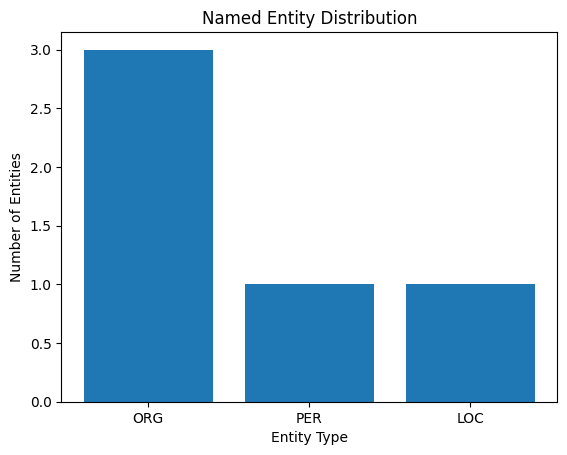

In [15]:
plt.bar(
entity_count.keys(),
entity_count.values()
)
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.title("Named Entity Distribution")
plt.show()